In [ ]:
%pip install scikit-learn==1.8.0 lightgbm==4.7.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 41.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 58.7 MB/s eta 0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1
  Attempting uninstall: lightgbm
    Found existing installation: lightgbm 4.6.0
    Uninstalling lightgbm-4.6.0:
      Successfully uninstalled lightgbm-4.6.0


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving train.csv to train.csv


In [ ]:
df = pd.read_csv('/content/train.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Dataset loaded successfully!
Dataset shape: (188533, 13)


,id,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,0,MINI,Cooper S Base,2007,213000,Gasoline,172.0HP 1.6L 4 Cylinder Engine Gasoline Fuel,A/T,Yellow,Gray,None reported,Yes,4200
1,1,Lincoln,LS V8,2002,143250,Gasoline,252.0HP 3.9L 8 Cylinder Engine Gasoline Fuel,A/T,Silver,Beige,At least 1 accident or damage reported,Yes,4999
2,2,Chevrolet,Silverado 2500 LT,2002,136731,E85 Flex Fuel,320.0HP 5.3L 8 Cylinder Engine Flex Fuel Capab...,A/T,Blue,Gray,None reported,Yes,13900
3,3,Genesis,G90 5.0 Ultimate,2017,19500,Gasoline,420.0HP 5.0L 8 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Black,Black,None reported,Yes,45000
4,4,Mercedes-Benz,Metris Base,2021,7388,Gasoline,208.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,7-Speed A/T,Black,Beige,None reported,Yes,97500



Column names:
['id', 'brand', 'model', 'model_year', 'milage', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title', 'price']



# 1\. Check Data Quality




In [ ]:
# 1. Check dataset size
print("Dataset shape:", df.shape)

# 2. Check column names and data types
df.info()

# 3. Count duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (188533, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 188533 entries, 0 to 188532
Data columns (total 13 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   id            188533 non-null  int64 
 1   brand         188533 non-null  object
 2   model         188533 non-null  object
 3   model_year    188533 non-null  int64 
 4   milage        188533 non-null  int64 
 5   fuel_type     183450 non-null  object
 6   engine        188533 non-null  object
 7   transmission  188533 non-null  object
 8   ext_col       188533 non-null  object
 9   int_col       188533 non-null  object
 10  accident      186081 non-null  object
 11  clean_title   167114 non-null  object
 12  price         188533 non-null  int64 
dtypes: int64(4), object(9)
memory usage: 18.7+ MB

Duplicate rows: 0


# 2\. Check missing values and target column

In [ ]:

# Check the target column
print("Column names:")
print(df.columns.tolist())

# Check missing values
print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check target price statistics
if "price" in df.columns:
    print("\nPrice statistics:")
    print(df["price"].describe())
elif "Price" in df.columns:
    print("\nPrice statistics:")
    print(df["Price"].describe())
else:
    print("\nPrice column not found. Check the column names above.")

Column names:
['id', 'brand', 'model', 'model_year', 'milage', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title', 'price']

Missing values:
fuel_type       5083
accident        2452
clean_title    21419
dtype: int64

Duplicate rows: 0

Price statistics:
count    1.885330e+05
mean     4.387802e+04
std      7.881952e+04
min      2.000000e+03
25%      1.700000e+04
50%      3.082500e+04
75%      4.990000e+04
max      2.954083e+06
Name: price, dtype: float64


# 3\. Clean the dataset

In [ ]:

# Create a copy of the original dataset
df_clean = df.copy()

# 1. Convert target price to numeric
df_clean["price"] = pd.to_numeric(
    df_clean["price"], errors="coerce"
)

# 2. Remove rows where target price is missing or invalid
before = len(df_clean)
df_clean = df_clean.dropna(subset=["price"])
print("Rows removed due to missing/invalid price:", before - len(df_clean))

# 3. Fill missing categorical values
categorical_cols = df_clean.select_dtypes(
    include=["object", "category"]
).columns

df_clean[categorical_cols] = (
    df_clean[categorical_cols].fillna("Unknown")
)

# 4. Remove duplicate rows, if any
before = len(df_clean)
df_clean = df_clean.drop_duplicates()
print("Duplicate rows removed:", before - len(df_clean))

# 5. Verify cleaning
print("\nCleaned dataset shape:", df_clean.shape)
print("\nRemaining missing values:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

display(df_clean.head())

Rows removed due to missing/invalid price: 0
Duplicate rows removed: 0

Cleaned dataset shape: (188533, 13)

Remaining missing values:
Series([], dtype: int64)


,id,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,0,MINI,Cooper S Base,2007,213000,Gasoline,172.0HP 1.6L 4 Cylinder Engine Gasoline Fuel,A/T,Yellow,Gray,None reported,Yes,4200
1,1,Lincoln,LS V8,2002,143250,Gasoline,252.0HP 3.9L 8 Cylinder Engine Gasoline Fuel,A/T,Silver,Beige,At least 1 accident or damage reported,Yes,4999
2,2,Chevrolet,Silverado 2500 LT,2002,136731,E85 Flex Fuel,320.0HP 5.3L 8 Cylinder Engine Flex Fuel Capab...,A/T,Blue,Gray,None reported,Yes,13900
3,3,Genesis,G90 5.0 Ultimate,2017,19500,Gasoline,420.0HP 5.0L 8 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Black,Black,None reported,Yes,45000
4,4,Mercedes-Benz,Metris Base,2021,7388,Gasoline,208.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,7-Speed A/T,Black,Beige,None reported,Yes,97500


# 4\. Visualize the price distribution

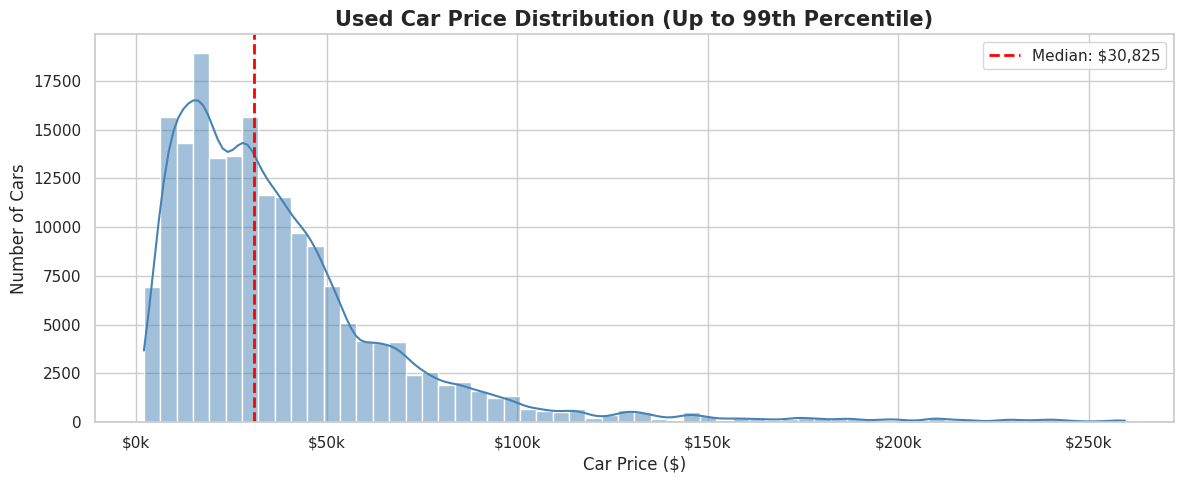


Price Percentile Summary:


,Percentile,Price ($)
0,Minimum (0%),"$2,000"
1,25th Percentile,"$17,000"
2,Median (50%),"$30,825"
3,75th Percentile,"$49,900"
4,90th Percentile,"$78,500"
5,95th Percentile,"$107,900"
6,99th Percentile,"$259,500"
7,Maximum (100%),"$2,954,083"


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker
import pandas as pd

# Price data
prices = df_clean["price"]

# Focus on 99% of cars for better visualization
upper_limit = prices.quantile(0.99)
prices_visual = prices[prices <= upper_limit]

sns.set_theme(style="whitegrid")

# 1. PRICE DISTRIBUTION HISTOGRAM

plt.figure(figsize=(12, 5))

sns.histplot(
    prices_visual,
    bins=60,
    kde=True,
    color="steelblue",
    edgecolor="white"
)

# Median price line
median_price = prices.median()

plt.axvline(
    median_price,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Median: ${median_price:,.0f}"
)

plt.title(
    "Used Car Price Distribution (Up to 99th Percentile)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Car Price ($)")
plt.ylabel("Number of Cars")

# Format X-axis prices
plt.gca().xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f"${x/1000:,.0f}k")
)

plt.legend()
plt.tight_layout()
plt.show()


# 2. PRICE PERCENTILE SUMMARY TABLE

percentiles = {
    "Minimum (0%)": prices.min(),
    "25th Percentile": prices.quantile(0.25),
    "Median (50%)": prices.quantile(0.50),
    "75th Percentile": prices.quantile(0.75),
    "90th Percentile": prices.quantile(0.90),
    "95th Percentile": prices.quantile(0.95),
    "99th Percentile": prices.quantile(0.99),
    "Maximum (100%)": prices.max()
}

percentile_df = pd.DataFrame(
    percentiles.items(),
    columns=["Percentile", "Price ($)"]
)

# Format prices
percentile_df["Price ($)"] = percentile_df["Price ($)"].apply(
    lambda x: f"${x:,.0f}"
)

print("\nPrice Percentile Summary:")
display(percentile_df)

# 5\. Separate features and target

In [ ]:

# Separate input features and target
X = df_clean.drop(columns=["price", "id"])
y = df_clean["price"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget preview:")
display(y.head())

Features shape: (188533, 11)
Target shape: (188533,)

Feature columns:
['brand', 'model', 'model_year', 'milage', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title']

Target preview:


,price
0,4200
1,4999
2,13900
3,45000
4,97500


# 6\. Split the dataset

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Training target samples:", y_train.shape[0])
print("Testing target samples:", y_test.shape[0])

Training samples: 150826
Testing samples: 37707
Training target samples: 150826
Testing target samples: 37707


# 7\. Preprocess the features

In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
print("\nPreprocessing pipeline created successfully!")

Numerical features: ['model_year', 'milage']
Categorical features: ['brand', 'model', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title']

Preprocessing pipeline created successfully!


# 8\. Training Models

## 8.1 Linear Regression

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    mean_absolute_percentage_error,
    r2_score
)
import numpy as np
import pandas as pd

# 1. Create model pipeline
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

# 2. Train the model
linear_model.fit(X_train, y_train)

# 3. Predict prices on test data
y_pred_linear = linear_model.predict(X_test)

# 4. Evaluate performance
mae = mean_absolute_error(y_test, y_pred_linear)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_linear))
r2 = r2_score(y_test, y_pred_linear)
mape = mean_absolute_percentage_error(y_test, y_pred_linear) * 100
medae = median_absolute_error(y_test, y_pred_linear)

# 5. Display results
linear_results = pd.DataFrame({
    "Metric": [
        "Mean Absolute Error (MAE)",
        "Root Mean Squared Error (RMSE)",
        "R² Score",
        "Mean Absolute Percentage Error (MAPE)",
        "Median Absolute Error (MedAE)"
    ],
    "Value": [
        f"${mae:,.2f}",
        f"${rmse:,.2f}",
        f"{r2:.4f}",
        f"{mape:.2f}%",
        f"${medae:,.2f}"
    ]
})

print("LINEAR REGRESSION - MODEL EVALUATION")
display(linear_results)

LINEAR REGRESSION - MODEL EVALUATION


,Metric,Value
0,Mean Absolute Error (MAE),"$21,615.69"
1,Root Mean Squared Error (RMSE),"$69,309.51"
2,R² Score,0.1362
3,Mean Absolute Percentage Error (MAPE),66.59%
4,Median Absolute Error (MedAE),"$11,028.93"


## 8.2 Random Forest Regressor


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    mean_absolute_percentage_error,
    r2_score
)
import numpy as np
import pandas as pd

# 1. Preprocessing for tree-based models
numeric_transformer_tree = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer_tree = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=20
    ))
])

preprocessor_tree = ColumnTransformer(transformers=[
    ("num", numeric_transformer_tree, numeric_features),
    ("cat", categorical_transformer_tree, categorical_features)
])

# 2. Create Random Forest pipeline
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor_tree),
    ("model", RandomForestRegressor(
        n_estimators=80,
        max_depth=20,
        min_samples_leaf=2,
        max_features=0.5,
        random_state=42,
        n_jobs=-1
    ))
])

# 3. Train the model
rf_model.fit(X_train, y_train)

# 4. Predict test prices
y_pred_rf = rf_model.predict(X_test)

# 5. Evaluate performance
rf_mae = mean_absolute_error(y_test, y_pred_rf)
rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
rf_r2 = r2_score(y_test, y_pred_rf)
rf_mape = mean_absolute_percentage_error(y_test, y_pred_rf) * 100
rf_medae = median_absolute_error(y_test, y_pred_rf)

# 6. Display results
rf_results = pd.DataFrame({
    "Metric": [
        "Mean Absolute Error (MAE)",
        "Root Mean Squared Error (RMSE)",
        "R² Score",
        "Mean Absolute Percentage Error (MAPE)",
        "Median Absolute Error (MedAE)"
    ],
    "Value": [
        f"${rf_mae:,.2f}",
        f"${rf_rmse:,.2f}",
        f"{rf_r2:.4f}",
        f"{rf_mape:.2f}%",
        f"${rf_medae:,.2f}"
    ]
})

print("RANDOM FOREST - MODEL EVALUATION")
display(rf_results)

RANDOM FOREST - MODEL EVALUATION


,Metric,Value
0,Mean Absolute Error (MAE),"$20,795.76"
1,Root Mean Squared Error (RMSE),"$70,217.56"
2,R² Score,0.1134
3,Mean Absolute Percentage Error (MAPE),58.12%
4,Median Absolute Error (MedAE),"$9,098.13"


## 8.3 XGBoost Regressor

In [ ]:
#Install XGBoost
%pip install -q xgboost

In [ ]:
from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    mean_absolute_percentage_error,
    r2_score
)
import numpy as np
import pandas as pd

# 1. Create the XGBoost model pipeline
xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor_tree),
    ("model", XGBRegressor(
        n_estimators=500,
        max_depth=8,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    ))
])

# 2. Train the model
xgb_model.fit(X_train, y_train)

# 3. Predict test prices
y_pred_xgb = xgb_model.predict(X_test)

# 4. Evaluate performance
xgb_mae = mean_absolute_error(y_test, y_pred_xgb)
xgb_rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
xgb_r2 = r2_score(y_test, y_pred_xgb)
xgb_mape = mean_absolute_percentage_error(y_test, y_pred_xgb) * 100
xgb_medae = median_absolute_error(y_test, y_pred_xgb)

# 5. Display results
xgb_results = pd.DataFrame({
    "Metric": [
        "Mean Absolute Error (MAE)",
        "Root Mean Squared Error (RMSE)",
        "R² Score",
        "Mean Absolute Percentage Error (MAPE)",
        "Median Absolute Error (MedAE)"
    ],
    "Value": [
        f"${xgb_mae:,.2f}",
        f"${xgb_rmse:,.2f}",
        f"{xgb_r2:.4f}",
        f"{xgb_mape:.2f}%",
        f"${xgb_medae:,.2f}"
    ]
})

print("XGBOOST - MODEL EVALUATION")
display(xgb_results)

XGBOOST - MODEL EVALUATION


,Metric,Value
0,Mean Absolute Error (MAE),"$20,367.09"
1,Root Mean Squared Error (RMSE),"$71,614.87"
2,R² Score,0.0778
3,Mean Absolute Percentage Error (MAPE),56.98%
4,Median Absolute Error (MedAE),"$8,787.39"


In [ ]:

import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(xgb_model, "models/xgboost.pkl", compress=3)

print("XGBoost model saved successfully!")
print("File size:", os.path.getsize("models/xgboost.pkl"), "bytes")


XGBoost model saved successfully!
File size: 1079804 bytes


## 8.4 LightGBM Regressor

In [ ]:
%pip install -q lightgbm

In [ ]:
from lightgbm import LGBMRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    mean_absolute_percentage_error,
    r2_score
)
import numpy as np
import pandas as pd

# 1. Create LightGBM pipeline
lgbm_model = Pipeline(steps=[
    ("preprocessor", preprocessor_tree),
    ("model", LGBMRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=10,
        num_leaves=31,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ))
])

# 2. Train the model
lgbm_model.fit(X_train, y_train)

# 3. Predict prices on test data
y_pred_lgbm = lgbm_model.predict(X_test)

# 4. Evaluate performance
lgbm_mae = mean_absolute_error(y_test, y_pred_lgbm)
lgbm_rmse = np.sqrt(mean_squared_error(y_test, y_pred_lgbm))
lgbm_r2 = r2_score(y_test, y_pred_lgbm)
lgbm_mape = mean_absolute_percentage_error(y_test, y_pred_lgbm) * 100
lgbm_medae = median_absolute_error(y_test, y_pred_lgbm)

# 5. Display results
lgbm_results = pd.DataFrame({
    "Metric": [
        "Mean Absolute Error (MAE)",
        "Root Mean Squared Error (RMSE)",
        "R² Score",
        "Mean Absolute Percentage Error (MAPE)",
        "Median Absolute Error (MedAE)"
    ],
    "Value": [
        f"${lgbm_mae:,.2f}",
        f"${lgbm_rmse:,.2f}",
        f"{lgbm_r2:.4f}",
        f"{lgbm_mape:.2f}%",
        f"${lgbm_medae:,.2f}"
    ]
})

print("LIGHTGBM - MODEL EVALUATION")
display(lgbm_results)

LIGHTGBM - MODEL EVALUATION


,Metric,Value
0,Mean Absolute Error (MAE),"$20,010.72"
1,Root Mean Squared Error (RMSE),"$68,336.49"
2,R² Score,0.1603
3,Mean Absolute Percentage Error (MAPE),55.93%
4,Median Absolute Error (MedAE),"$8,802.19"


## 8.5 Log-Target LightGBM

In [ ]:
import numpy as np
import pandas as pd

from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from lightgbm import LGBMRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    mean_absolute_percentage_error,
    r2_score
)

# 1. Create Log-Target LightGBM pipeline
lgbm_log_model = TransformedTargetRegressor(
    regressor=Pipeline(steps=[
        ("preprocessor", preprocessor_tree),
        ("model", LGBMRegressor(
            n_estimators=700,
            learning_rate=0.03,
            max_depth=10,
            num_leaves=31,
            colsample_bytree=0.8,
            random_state=42,
            n_jobs=-1,
            verbosity=-1
        ))
    ]),
    func=np.log1p,
    inverse_func=np.expm1
)

# 2. Train the model
lgbm_log_model.fit(X_train, y_train)

# 3. Predict prices on test data
# Predictions are automatically converted back to dollars
y_pred_lgbm_log = lgbm_log_model.predict(X_test)

# 4. Evaluate performance
lgbm_log_mae = mean_absolute_error(y_test, y_pred_lgbm_log)
lgbm_log_rmse = np.sqrt(mean_squared_error(y_test, y_pred_lgbm_log))
lgbm_log_r2 = r2_score(y_test, y_pred_lgbm_log)
lgbm_log_mape = mean_absolute_percentage_error(y_test, y_pred_lgbm_log) * 100
lgbm_log_medae = median_absolute_error(y_test, y_pred_lgbm_log)

# 5. Display results
lgbm_log_results = pd.DataFrame({
    "Metric": [
        "Mean Absolute Error (MAE)",
        "Root Mean Squared Error (RMSE)",
        "R² Score",
        "Mean Absolute Percentage Error (MAPE)",
        "Median Absolute Error (MedAE)"
    ],
    "Value": [
        f"${lgbm_log_mae:,.2f}",
        f"${lgbm_log_rmse:,.2f}",
        f"{lgbm_log_r2:.4f}",
        f"{lgbm_log_mape:.2f}%",
        f"${lgbm_log_medae:,.2f}"
    ]
})

print("LOG-TARGET LIGHTGBM - MODEL EVALUATION")
display(lgbm_log_results)

LOG-TARGET LIGHTGBM - MODEL EVALUATION


,Metric,Value
0,Mean Absolute Error (MAE),"$17,313.72"
1,Root Mean Squared Error (RMSE),"$68,913.58"
2,R² Score,0.1460
3,Mean Absolute Percentage Error (MAPE),37.99%
4,Median Absolute Error (MedAE),"$6,733.52"


## 8.6 CatBoost Regressor

In [ ]:
%pip install -q catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 6.2 MB/s eta 0:00:00


In [ ]:
from catboost import CatBoostRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    mean_absolute_percentage_error,
    r2_score
)
import numpy as np
import pandas as pd

# 1. Create CatBoost pipeline
cat_model = Pipeline(steps=[
    ("preprocessor", preprocessor_tree),
    ("model", CatBoostRegressor(
        iterations=500,
        depth=8,
        learning_rate=0.05,
        loss_function="RMSE",
        random_seed=42,
        verbose=100,
        thread_count=-1,
        allow_writing_files=False
    ))
])

# 2. Train the model
cat_model.fit(X_train, y_train)

# 3. Predict prices on test data
y_pred_cat = cat_model.predict(X_test)

# 4. Evaluate performance
cat_mae = mean_absolute_error(y_test, y_pred_cat)
cat_rmse = np.sqrt(mean_squared_error(y_test, y_pred_cat))
cat_r2 = r2_score(y_test, y_pred_cat)
cat_mape = mean_absolute_percentage_error(y_test, y_pred_cat) * 100
cat_medae = median_absolute_error(y_test, y_pred_cat)

# 5. Display results
cat_results = pd.DataFrame({
    "Metric": [
        "Mean Absolute Error (MAE)",
        "Root Mean Squared Error (RMSE)",
        "R² Score",
        "Mean Absolute Percentage Error (MAPE)",
        "Median Absolute Error (MedAE)"
    ],
    "Value": [
        f"${cat_mae:,.2f}",
        f"${cat_rmse:,.2f}",
        f"{cat_r2:.4f}",
        f"{cat_mape:.2f}%",
        f"${cat_medae:,.2f}"
    ]
})

print("CATBOOST - MODEL EVALUATION")
display(cat_results)

0:	learn: 79410.5103974	total: 127ms	remaining: 1m 3s
100:	learn: 72420.7737956	total: 4.76s	remaining: 18.8s
200:	learn: 70690.8630368	total: 10.3s	remaining: 15.3s
300:	learn: 69158.3821781	total: 14.5s	remaining: 9.59s
400:	learn: 67699.1892480	total: 18.9s	remaining: 4.68s
499:	learn: 66336.3169055	total: 24.1s	remaining: 0us
CATBOOST - MODEL EVALUATION


,Metric,Value
0,Mean Absolute Error (MAE),"$20,465.39"
1,Root Mean Squared Error (RMSE),"$69,938.84"
2,R² Score,0.1204
3,Mean Absolute Percentage Error (MAPE),58.86%
4,Median Absolute Error (MedAE),"$9,578.67"


In [ ]:
model_names = [
    "linear_model",
    "rf_model",
    "xgb_model",
    "lgbm_model",
    "cat_model",
    "lgbm_log_model"
]

for name in model_names:
    obj = globals().get(name)
    if obj is not None:
        print(f"✅ {name}: {type(obj).__name__}")
    else:
        print(f"❌ {name}: not found")


✅ linear_model: Pipeline
✅ rf_model: Pipeline
✅ xgb_model: Pipeline
✅ lgbm_model: Pipeline
✅ cat_model: Pipeline
✅ lgbm_log_model: TransformedTargetRegressor


# 9\. Model Evaluation

## 9.1 Compare All Six Models

MODEL PERFORMANCE COMPARISON


,Model,MAE,RMSE,R2,MAPE (%),MedAE
0,Log-Target LightGBM,"$17,313.72","$68,913.58",0.1460,37.99%,"$6,733.52"
1,LightGBM,"$20,010.72","$68,336.49",0.1603,55.93%,"$8,802.19"
2,XGBoost,"$20,367.09","$71,614.87",0.0778,56.98%,"$8,787.39"
3,CatBoost,"$20,465.39","$69,938.84",0.1204,58.86%,"$9,578.67"
4,Random Forest,"$20,795.76","$70,217.56",0.1134,58.12%,"$9,098.13"
5,Linear Regression,"$21,615.69","$69,309.51",0.1362,66.59%,"$11,028.93"


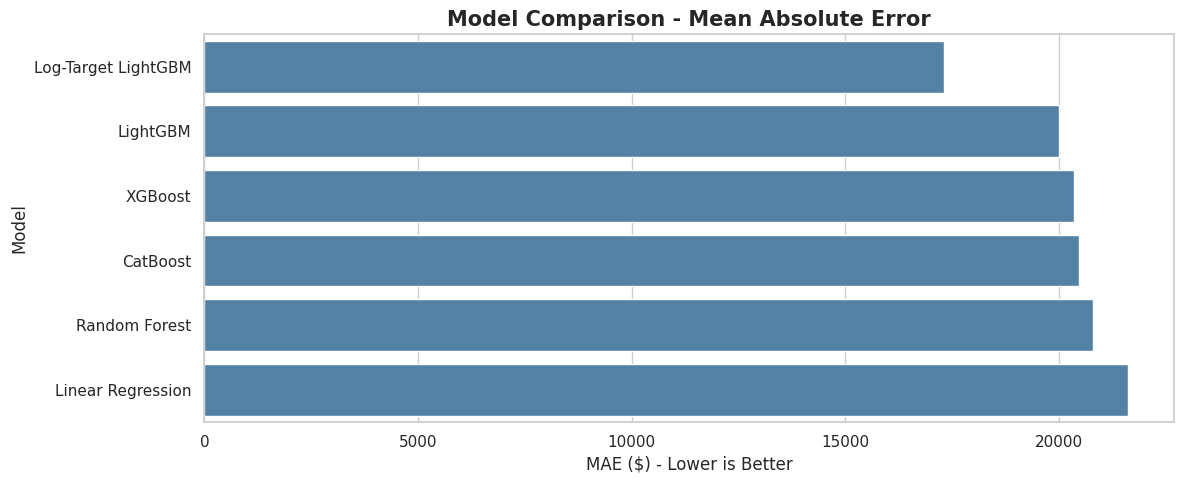


BEST MODEL BASED ON MAE
-----------------------------------
Model: Log-Target LightGBM
MAE: $17,313.72
RMSE: $68,913.58
R2 Score: 0.1460
MAPE: 37.99%
MedAE: $6,733.52


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Collect results from all six models
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "XGBoost",
        "LightGBM",
        "Log-Target LightGBM",
        "CatBoost"
    ],
    "MAE": [
        mae, rf_mae, xgb_mae,
        lgbm_mae, lgbm_log_mae, cat_mae
    ],
    "RMSE": [
        rmse, rf_rmse, xgb_rmse,
        lgbm_rmse, lgbm_log_rmse, cat_rmse
    ],
    "R2": [
        r2, rf_r2, xgb_r2,
        lgbm_r2, lgbm_log_r2, cat_r2
    ],
    "MAPE (%)": [
        mape, rf_mape, xgb_mape,
        lgbm_mape, lgbm_log_mape, cat_mape
    ],
    "MedAE": [
        medae, rf_medae, xgb_medae,
        lgbm_medae, lgbm_log_medae, cat_medae
    ]
})

# 2. Sort models by MAE
results = results.sort_values(
    by="MAE", ascending=True
).reset_index(drop=True)

# Display formatted comparison table
print("MODEL PERFORMANCE COMPARISON")

display(
    results.style
    .format({
        "MAE": "${:,.2f}",
        "RMSE": "${:,.2f}",
        "R2": "{:.4f}",
        "MAPE (%)": "{:.2f}%",
        "MedAE": "${:,.2f}"
    })
    .highlight_min(
        subset=["MAE", "RMSE", "MAPE (%)", "MedAE"],
        props="background-color: #d4edda; color: #000000; font-weight: bold;"
    )
    .highlight_max(
        subset=["R2"],
        props="background-color: #d4edda; color: #000000; font-weight: bold;"
    )
)

# 4. Visualize MAE comparison
plt.figure(figsize=(12, 5))

sns.barplot(
    data=results,
    x="MAE",
    y="Model",
    color="steelblue"
)

plt.title(
    "Model Comparison - Mean Absolute Error",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("MAE ($) - Lower is Better")
plt.ylabel("Model")

plt.tight_layout()
plt.show()

# 5. Identify best model based on MAE
best_model = results.iloc[0]

print("\nBEST MODEL BASED ON MAE")
print("-" * 35)
print(f"Model: {best_model['Model']}")
print(f"MAE: ${best_model['MAE']:,.2f}")
print(f"RMSE: ${best_model['RMSE']:,.2f}")
print(f"R2 Score: {best_model['R2']:.4f}")
print(f"MAPE: {best_model['MAPE (%)']:.2f}%")
print(f"MedAE: ${best_model['MedAE']:,.2f}")


## 9.2 Error Analysis

TOP 3 MODELS FOR ERROR ANALYSIS


,Model,MAE,RMSE,R2,MAPE (%),MedAE
0,Log-Target LightGBM,17313.721025,68913.583517,0.146023,37.988208,6733.515955
1,LightGBM,20010.719959,68336.486906,0.160266,55.930829,8802.190042
2,XGBoost,20367.085938,71614.873986,0.077762,56.978428,8787.394531


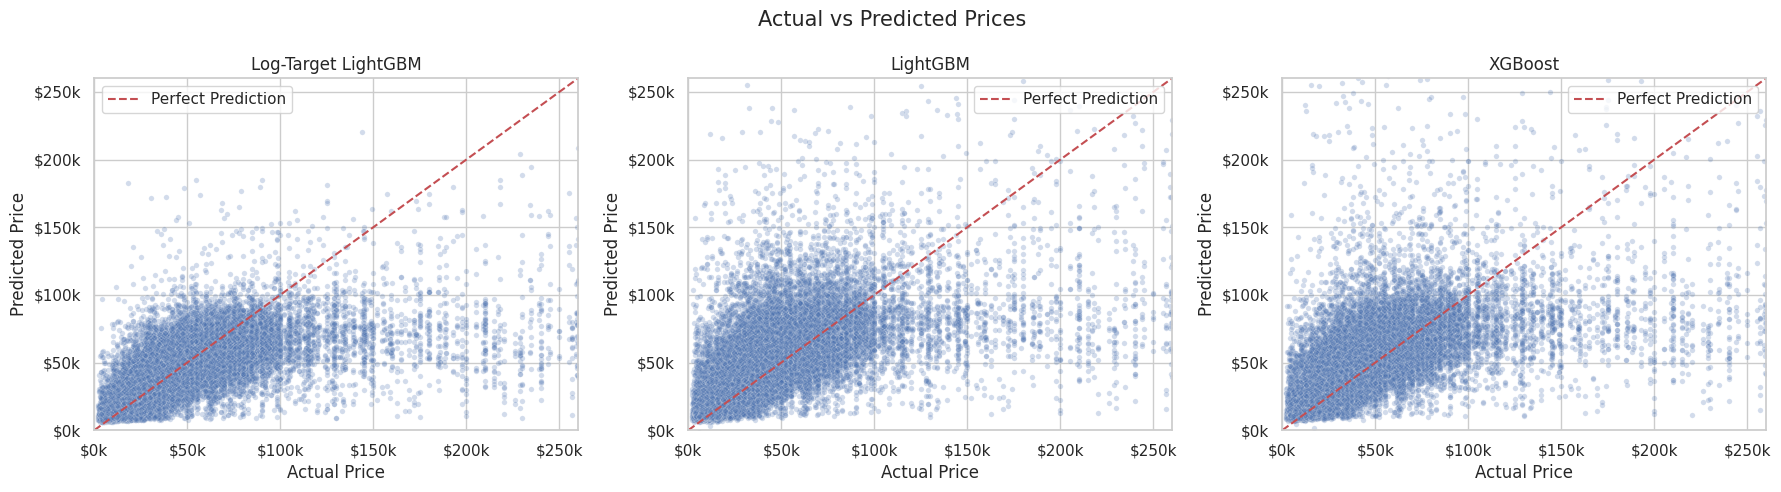

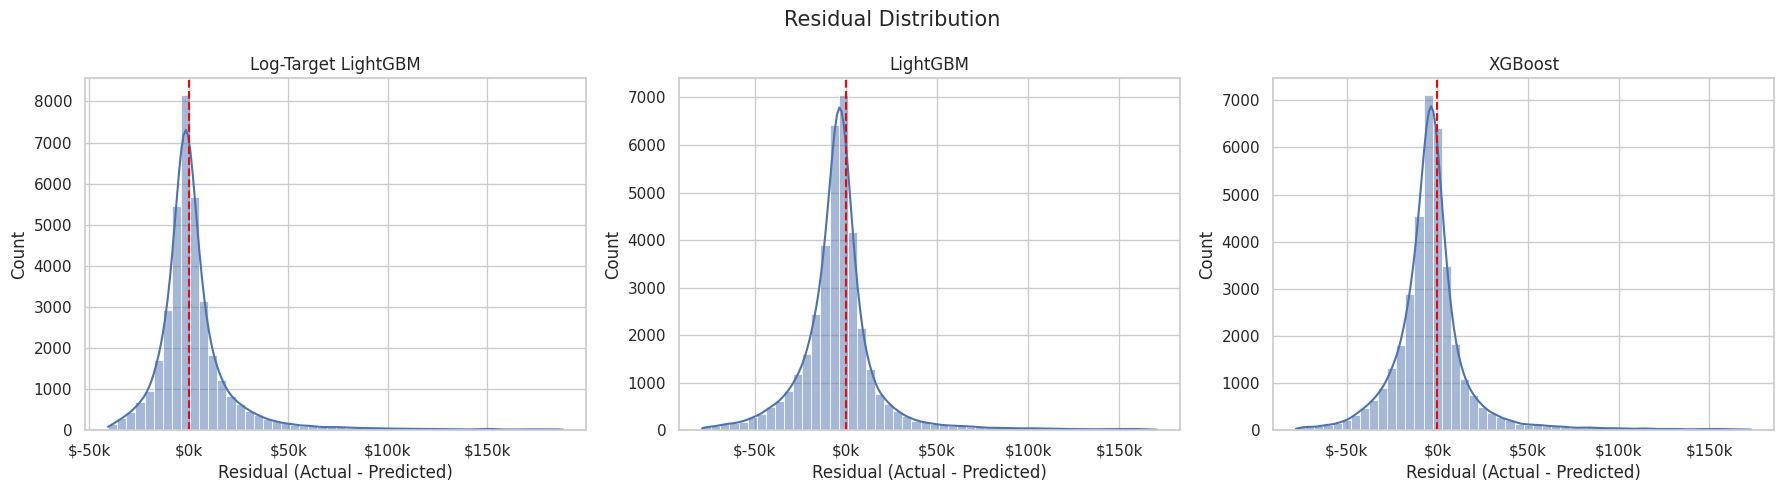

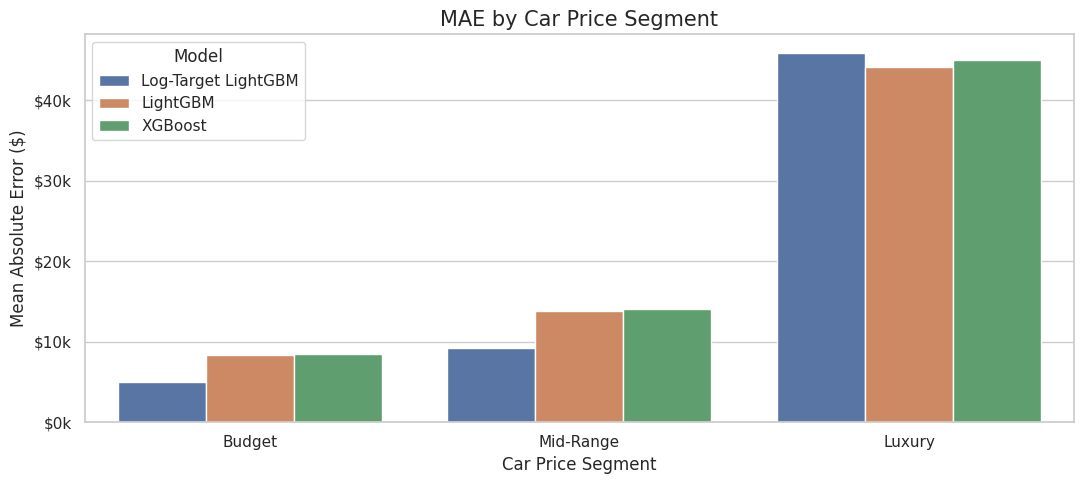


ERROR BY PRICE SEGMENT


Segment,Budget,Luxury,Mid-Range
Model,,,
LightGBM,"$8,342.36","$44,141.80","$13,828.94"
Log-Target LightGBM,"$4,965.42","$45,881.15","$9,243.34"
XGBoost,"$8,477.24","$44,963.28","$14,064.41"


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# 1. Map model names to existing predictions
predictions = {
    "Linear Regression": y_pred_linear,
    "Random Forest": y_pred_rf,
    "XGBoost": y_pred_xgb,
    "LightGBM": y_pred_lgbm,
    "Log-Target LightGBM": y_pred_lgbm_log,
    "CatBoost": y_pred_cat
}

# Select top 3 models based on MAE
top_models = results.nsmallest(3, "MAE")["Model"].tolist()

# Convert actual prices to NumPy array
actual = np.asarray(y_test).ravel()

# Focus visualization on cars <= 99th percentile
price_limit = np.percentile(actual, 99)
mask = actual <= price_limit

# Format prices as $20k, $40k, etc.
money_fmt = FuncFormatter(lambda x, pos: f"${x/1000:,.0f}k")

print("TOP 3 MODELS FOR ERROR ANALYSIS")
display(results.head(3))

# 2. Actual vs Predicted Prices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, name in zip(axes, top_models):
    predicted = np.asarray(predictions[name]).ravel()

    sns.scatterplot(
        x=actual[mask],
        y=predicted[mask],
        alpha=0.25,
        s=15,
        ax=ax
    )

    ax.plot(
        [0, price_limit],
        [0, price_limit],
        "r--",
        label="Perfect Prediction"
    )

    ax.set_xlim(0, price_limit)
    ax.set_ylim(0, price_limit)
    ax.set_title(name)
    ax.set_xlabel("Actual Price")
    ax.set_ylabel("Predicted Price")
    ax.xaxis.set_major_formatter(money_fmt)
    ax.yaxis.set_major_formatter(money_fmt)
    ax.legend()

plt.suptitle("Actual vs Predicted Prices", fontsize=15)
plt.tight_layout()
plt.show()

# 3. Residual Distribution
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, name in zip(axes, top_models):
    predicted = np.asarray(predictions[name]).ravel()
    residuals = actual - predicted

    # Trim extreme residuals for visualization only
    low, high = np.percentile(residuals, [1, 99])
    visible_residuals = residuals[
        (residuals >= low) & (residuals <= high)
    ]

    sns.histplot(
        visible_residuals,
        bins=50,
        kde=True,
        ax=ax
    )

    ax.axvline(0, color="red", linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Residual (Actual - Predicted)")
    ax.xaxis.set_major_formatter(money_fmt)

plt.suptitle("Residual Distribution", fontsize=15)
plt.tight_layout()
plt.show()

# 4. Error by Price Segment
# Use quartiles of actual test prices to define segments
q25, q75 = np.percentile(actual, [25, 75])

segments = pd.cut(
    actual,
    bins=[-np.inf, q25, q75, np.inf],
    labels=["Budget", "Mid-Range", "Luxury"]
)

segment_results = []

for name in top_models:
    predicted = np.asarray(predictions[name]).ravel()
    absolute_errors = np.abs(actual - predicted)

    for segment in ["Budget", "Mid-Range", "Luxury"]:
        segment_mask = np.asarray(segments == segment)

        segment_results.append({
            "Model": name,
            "Segment": segment,
            "MAE": absolute_errors[segment_mask].mean()
        })

segment_df = pd.DataFrame(segment_results)

plt.figure(figsize=(11, 5))

sns.barplot(
    data=segment_df,
    x="Segment",
    y="MAE",
    hue="Model",
    order=["Budget", "Mid-Range", "Luxury"]
)

plt.title("MAE by Car Price Segment", fontsize=15)
plt.ylabel("Mean Absolute Error ($)")
plt.xlabel("Car Price Segment")
plt.gca().yaxis.set_major_formatter(money_fmt)
plt.tight_layout()
plt.show()

print("\nERROR BY PRICE SEGMENT")
display(
    segment_df.pivot(
        index="Model",
        columns="Segment",
        values="MAE"
    ).style.format("${:,.2f}")
)


## 9.3 Overfitting Analysis

TRAIN VS TEST PERFORMANCE


,Model,Train MAE,Test MAE,Gap ($),Gap (%)
0,Log-Target LightGBM,"$17,134.14","$17,313.72",$179.58,1.05%
1,LightGBM,"$19,386.43","$20,010.72",$624.29,3.22%
2,XGBoost,"$17,605.33","$20,367.09","$2,761.76",15.69%


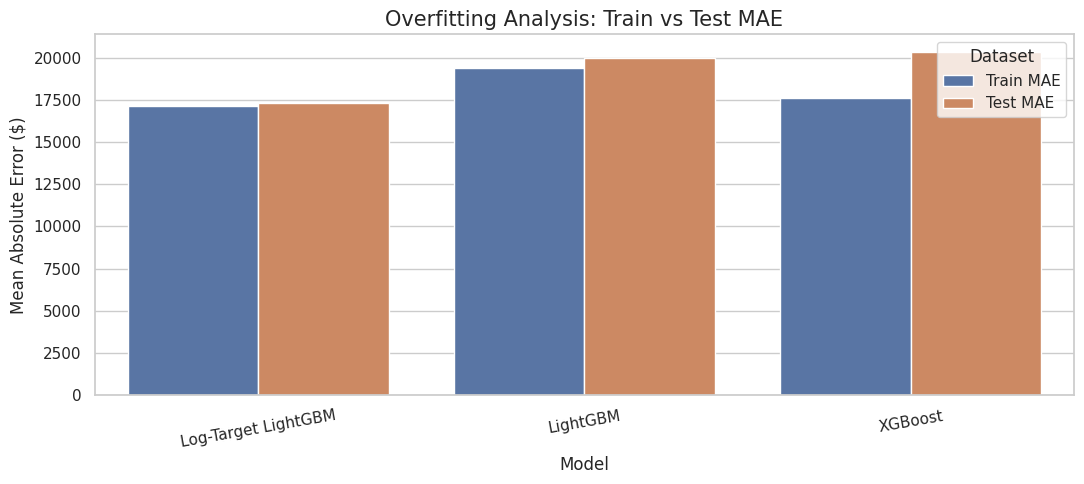

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error

# 1. Select top 3 trained models
top_models = {
    "Log-Target LightGBM": lgbm_log_model,
    "LightGBM": lgbm_model,
    "XGBoost": xgb_model
}

# 2. Calculate training and test MAE
overfitting_results = []

for name, model in top_models.items():

    # Predictions on training data
    train_pred = model.predict(X_train)

    # Predictions on test data
    test_pred = model.predict(X_test)

    # Calculate errors
    train_mae = mean_absolute_error(y_train, train_pred)
    test_mae = mean_absolute_error(y_test, test_pred)

    # Calculate generalization gap
    gap = test_mae - train_mae
    gap_pct = (gap / train_mae) * 100 if train_mae != 0 else np.nan

    overfitting_results.append({
        "Model": name,
        "Train MAE": train_mae,
        "Test MAE": test_mae,
        "Gap ($)": gap,
        "Gap (%)": gap_pct
    })

# 3. Create comparison DataFrame
overfitting_df = pd.DataFrame(overfitting_results)

print("TRAIN VS TEST PERFORMANCE")

display(
    overfitting_df.style.format({
        "Train MAE": "${:,.2f}",
        "Test MAE": "${:,.2f}",
        "Gap ($)": "${:,.2f}",
        "Gap (%)": "{:.2f}%"
    })
)

# 4. Visualize training vs test MAE
plot_df = overfitting_df.melt(
    id_vars="Model",
    value_vars=["Train MAE", "Test MAE"],
    var_name="Dataset",
    value_name="MAE"
)

plt.figure(figsize=(11, 5))

sns.barplot(
    data=plot_df,
    x="Model",
    y="MAE",
    hue="Dataset"
)

plt.title("Overfitting Analysis: Train vs Test MAE", fontsize=15)
plt.xlabel("Model")
plt.ylabel("Mean Absolute Error ($)")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()


## 9.4 Cross-Validation

Running 5-fold CV for Log-Target LightGBM...
Running 5-fold CV for LightGBM...
Running 5-fold CV for XGBoost...

5-FOLD CROSS-VALIDATION RESULTS


,Model,Mean CV MAE,Std CV MAE,Mean CV RMSE,Mean CV R2,Mean Train MAE,Mean Gap ($)
0,Log-Target LightGBM,"$17,424.31",$562.20,"$74,524.73",0.1258,"$17,102.84",$321.47
1,LightGBM,"$20,155.12",$381.25,"$74,404.55",0.1282,"$19,370.36",$784.76
2,XGBoost,"$20,315.60",$450.04,"$77,190.96",0.0608,"$17,383.81","$2,931.79"


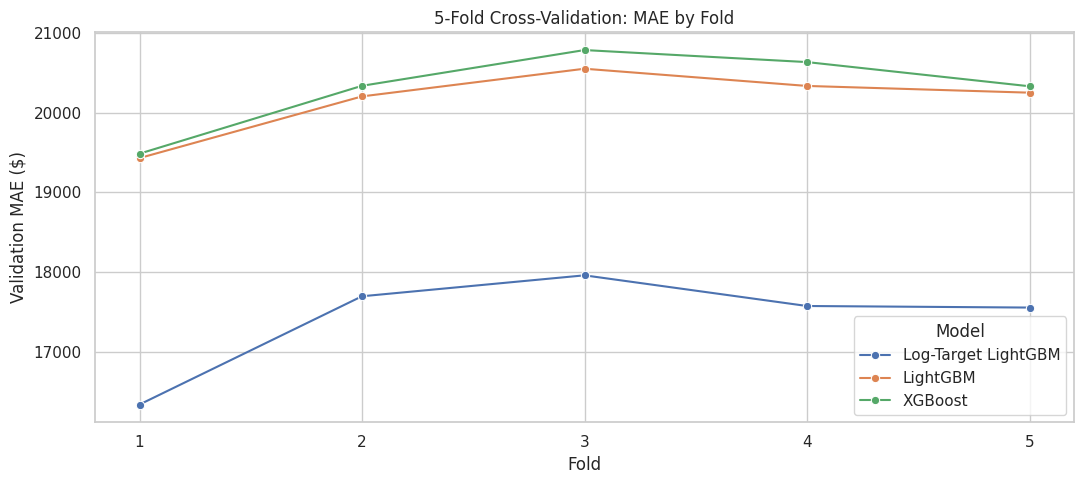


BEST MODEL BASED ON CROSS-VALIDATION
Model: Log-Target LightGBM
Mean CV MAE: $17,424.31
Std CV MAE: $562.20


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import KFold, cross_validate
from sklearn.base import clone

# 1. Select shortlisted models
cv_models = {
    "Log-Target LightGBM": lgbm_log_model,
    "LightGBM": lgbm_model,
    "XGBoost": xgb_model
}

# 2. Define 5-fold cross-validation
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 3. Evaluate each model
cv_results = []
fold_results = []

for name, model in cv_models.items():

    print(f"Running 5-fold CV for {name}...")

    scores = cross_validate(
        estimator=clone(model),
        X=X_train,
        y=y_train,
        cv=kf,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        n_jobs=1,
        return_train_score=True
    )

    # Convert negative scores to positive errors
    train_mae = -scores["train_MAE"]
    val_mae = -scores["test_MAE"]
    val_rmse = -scores["test_RMSE"]
    val_r2 = scores["test_R2"]

    cv_results.append({
        "Model": name,
        "Mean CV MAE": val_mae.mean(),
        "Std CV MAE": val_mae.std(),
        "Mean CV RMSE": val_rmse.mean(),
        "Mean CV R2": val_r2.mean(),
        "Mean Train MAE": train_mae.mean(),
        "Mean Gap ($)": (
            val_mae.mean() - train_mae.mean()
        )
    })

    for fold, (train_error, val_error) in enumerate(
        zip(train_mae, val_mae), start=1
    ):
        fold_results.append({
            "Model": name,
            "Fold": fold,
            "Train MAE": train_error,
            "Validation MAE": val_error
        })

# 4. Create comparison table
cv_df = pd.DataFrame(cv_results)

cv_df = cv_df.sort_values(
    by="Mean CV MAE"
).reset_index(drop=True)

print("\n5-FOLD CROSS-VALIDATION RESULTS")

display(
    cv_df.style.format({
        "Mean CV MAE": "${:,.2f}",
        "Std CV MAE": "${:,.2f}",
        "Mean CV RMSE": "${:,.2f}",
        "Mean CV R2": "{:.4f}",
        "Mean Train MAE": "${:,.2f}",
        "Mean Gap ($)": "${:,.2f}"
    })
)

# 5. Visualize fold-wise validation MAE
fold_df = pd.DataFrame(fold_results)

plt.figure(figsize=(11, 5))

sns.lineplot(
    data=fold_df,
    x="Fold",
    y="Validation MAE",
    hue="Model",
    marker="o"
)

plt.title("5-Fold Cross-Validation: MAE by Fold")
plt.xlabel("Fold")
plt.ylabel("Validation MAE ($)")
plt.xticks([1, 2, 3, 4, 5])
plt.tight_layout()
plt.show()

# 6. Identify best model by mean CV MAE
best_cv = cv_df.iloc[0]

print("\nBEST MODEL BASED ON CROSS-VALIDATION")
print(f"Model: {best_cv['Model']}")
print(f"Mean CV MAE: ${best_cv['Mean CV MAE']:,.2f}")
print(f"Std CV MAE: ${best_cv['Std CV MAE']:,.2f}")


## 9.5 Hyperparameter Tuning


In [ ]:

import numpy as np
import pandas as pd

from sklearn.model_selection import RandomizedSearchCV, KFold
from sklearn.base import clone

# 1. Models to tune
tuning_models = {
    "Log-Target LightGBM": lgbm_log_model,
    "LightGBM": lgbm_model
}

# 2. Parameter search spaces
param_grids = {
    "Log-Target LightGBM": {
        "regressor__model__n_estimators": [400, 700, 1000],
        "regressor__model__learning_rate": [0.02, 0.03, 0.05],
        "regressor__model__max_depth": [6, 10, 14],
        "regressor__model__num_leaves": [15, 31, 63],
        "regressor__model__min_child_samples": [20, 40, 60],
        "regressor__model__colsample_bytree": [0.7, 0.8, 1.0]
    },

    "LightGBM": {
        "model__n_estimators": [300, 500, 800],
        "model__learning_rate": [0.02, 0.05, 0.08],
        "model__max_depth": [6, 10, 14],
        "model__num_leaves": [15, 31, 63],
        "model__min_child_samples": [20, 40, 60],
        "model__colsample_bytree": [0.7, 0.8, 1.0]
    }
}

# 3. Cross-validation setup
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

tuned_models = {}
tuning_results = []

# 4. Tune each model
for name, model in tuning_models.items():

    print(f"\nTuning {name}...")

    search = RandomizedSearchCV(
        estimator=clone(model),
        param_distributions=param_grids[name],
        n_iter=15,
        scoring="neg_mean_absolute_error",
        cv=kf,
        random_state=42,
        n_jobs=1,
        verbose=1,
        refit=True
    )

    search.fit(X_train, y_train)

    tuned_models[name] = search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best CV MAE": -search.best_score_,
        "Best Parameters": search.best_params_
    })

    print(f"Best CV MAE: ${-search.best_score_:,.2f}")
    print("Best Parameters:")
    print(search.best_params_)

# 5. Compare original and tuned models
tuning_df = pd.DataFrame(tuning_results)

original_cv = cv_df.set_index("Model")["Mean CV MAE"]

tuning_df["Original CV MAE"] = tuning_df["Model"].map(
    original_cv
)

tuning_df["Improvement ($)"] = (
    tuning_df["Original CV MAE"] -
    tuning_df["Best CV MAE"]
)

tuning_df["Improvement (%)"] = (
    tuning_df["Improvement ($)"] /
    tuning_df["Original CV MAE"] * 100
)
print("\nHYPERPARAMETER TUNING COMPARISON")

display(
    tuning_df.drop(columns=["Best Parameters"])
    .style.format({
        "Original CV MAE": "${:,.2f}",
        "Best CV MAE": "${:,.2f}",
        "Improvement ($)": "${:,.2f}",
        "Improvement (%)": "{:.2f}%"
    })
)



Tuning Log-Target LightGBM...
Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best CV MAE: $17,292.63
Best Parameters:
{'regressor__model__num_leaves': 31, 'regressor__model__n_estimators': 1000, 'regressor__model__min_child_samples': 20, 'regressor__model__max_depth': 14, 'regressor__model__learning_rate': 0.05, 'regressor__model__colsample_bytree': 1.0}

Tuning LightGBM...
Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best CV MAE: $19,920.64
Best Parameters:
{'model__num_leaves': 15, 'model__n_estimators': 800, 'model__min_child_samples': 60, 'model__max_depth': 14, 'model__learning_rate': 0.02, 'model__colsample_bytree': 0.7}

HYPERPARAMETER TUNING COMPARISON


,Model,Best CV MAE,Original CV MAE,Improvement ($),Improvement (%)
0,Log-Target LightGBM,"$17,292.63","$17,424.31",$131.68,0.76%
1,LightGBM,"$19,920.64","$20,155.12",$234.47,1.16%


In [ ]:
print("Dataset Features:")
print(X_train.columns.tolist())

Dataset Features:
['brand', 'model', 'model_year', 'milage', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title']


## 9.6 Feature Importance

FEATURE IMPORTANCE RANKING


,Feature,Importance,Std
0,model_year,"$5,233.85",$21.56
1,milage,"$4,170.01",$32.74
2,brand,"$1,125.31",$8.62
3,engine,"$1,004.79",$7.98
4,model,$498.64,$7.67
5,transmission,$248.61,$4.41
6,ext_col,$117.16,$2.67
7,accident,$101.03,$7.48
8,int_col,$97.69,$1.54
9,fuel_type,$74.62,$1.49


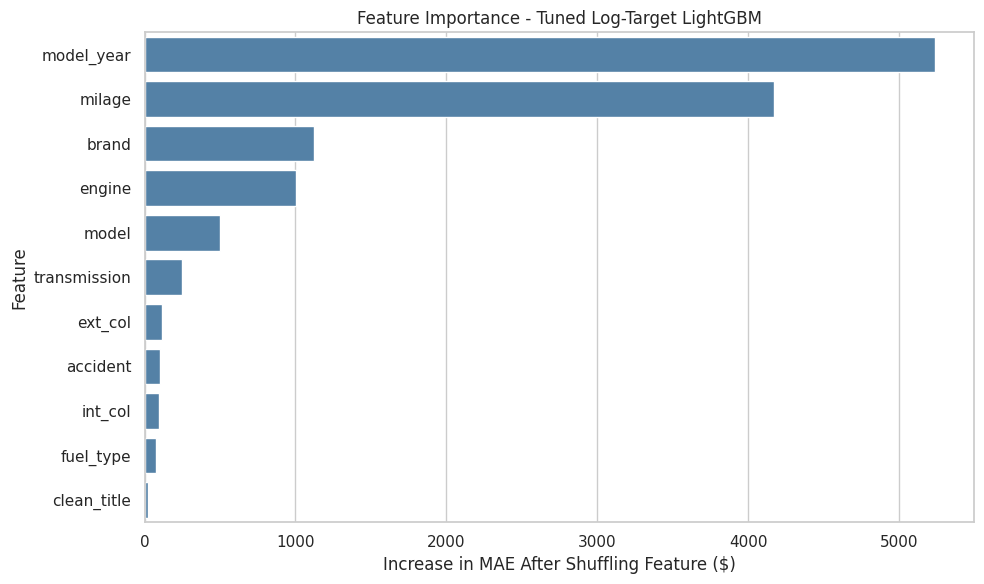

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.inspection import permutation_importance

# Use the tuned Log-Target LightGBM
best_model = tuned_models["Log-Target LightGBM"]

# Calculate permutation importance on training data
importance = permutation_importance(
    best_model,
    X_train,
    y_train,
    scoring="neg_mean_absolute_error",
    n_repeats=3,
    random_state=42,
    n_jobs=1
)

# Create importance table
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
}).sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("FEATURE IMPORTANCE RANKING")

display(
    importance_df.style.format({
        "Importance": "${:,.2f}",
        "Std": "${:,.2f}"
    })
)

# Visualize feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title("Feature Importance - Tuned Log-Target LightGBM")
plt.xlabel("Increase in MAE After Shuffling Feature ($)")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


# 10\. Export the final model from Google Colab

In [ ]:
import joblib

# Select the tuned Log-Target LightGBM model
final_model = tuned_models["Log-Target LightGBM"]

# Save the complete fitted pipeline and model
joblib.dump(final_model, "tuned_lightgbm_log.pkl")

print("Final model saved successfully!")

Final model saved successfully!


# 11\. Download the model

In [ ]:
from google.colab import files

files.download("tuned_lightgbm_log.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>